# Regression with Nested Cross-Validation
Wine Quality dataset (red and white wines)

The goal is to predict the quality score from the physicochemical variables.

If the same cross-validation is used to choose the hyperparameters and to report the result, the
result is optimistic, because we chose the hyperparameters that worked best on those folds. With
nested cross-validation we use two loops:

* Outer loop (5 folds): to estimate the performance on data not used for tuning.
* Inner loop (3 folds, `GridSearchCV`): to choose the hyperparameters using only the training
  part of each outer fold.

## 0. Libraries and plot style

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Colours for the plots
PLUM, PURPLE, LILAC = "#4A1942", "#7D3C98", "#C39BD3"
PINK, ROSE = "#E0719E", "#F5B7C8"
ORANGE, APRICOT = "#E8743B", "#F6A96B"
CREAM, INK = "#FDF1EC", "#3B2A3F"

PALETTE = [PURPLE, PINK, ORANGE, LILAC, APRICOT, PLUM, ROSE]
CLASS_ORDER = ["Low", "Medium", "High"]
CLASS_COLORS = {"Low": PURPLE, "Medium": PINK, "High": ORANGE}
TYPE_COLORS = {"red": PLUM, "white": APRICOT}
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", ["#FFFFFF", ROSE, PINK, PURPLE, PLUM])
CMAP_DIV = LinearSegmentedColormap.from_list("div", [PURPLE, LILAC, "#FFFFFF", APRICOT, ORANGE])

sns.set_theme(style="white", palette=PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#CBB8CF", "axes.labelcolor": INK, "axes.titlecolor": PLUM,
    "axes.titleweight": "semibold", "axes.titlesize": 12, "axes.grid": True,
    "grid.color": "#F1E4EC", "xtick.color": INK, "ytick.color": INK,
    "legend.frameon": False, "text.color": INK,
})

FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print("Figure saved ->", FIG_DIR / name)

In [2]:
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
RES_DIR = Path("../results")
RES_DIR.mkdir(exist_ok=True)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

## 1. Predictors and target

In [3]:
FEATURES = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar",
            "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
            "pH", "sulphates", "alcohol"] + ["is_red"]
TARGET = "quality"

wine = pd.read_csv("../data/wine_clean.csv")
X = wine[FEATURES].to_numpy()
y = wine[TARGET].to_numpy()
print("X:", X.shape, " y:", y.shape)

X: (5320, 12)  y: (5320,)


## 2. Nested cross-validation diagram

Figure saved -> ../results/figures/nested_cv_diagram.png


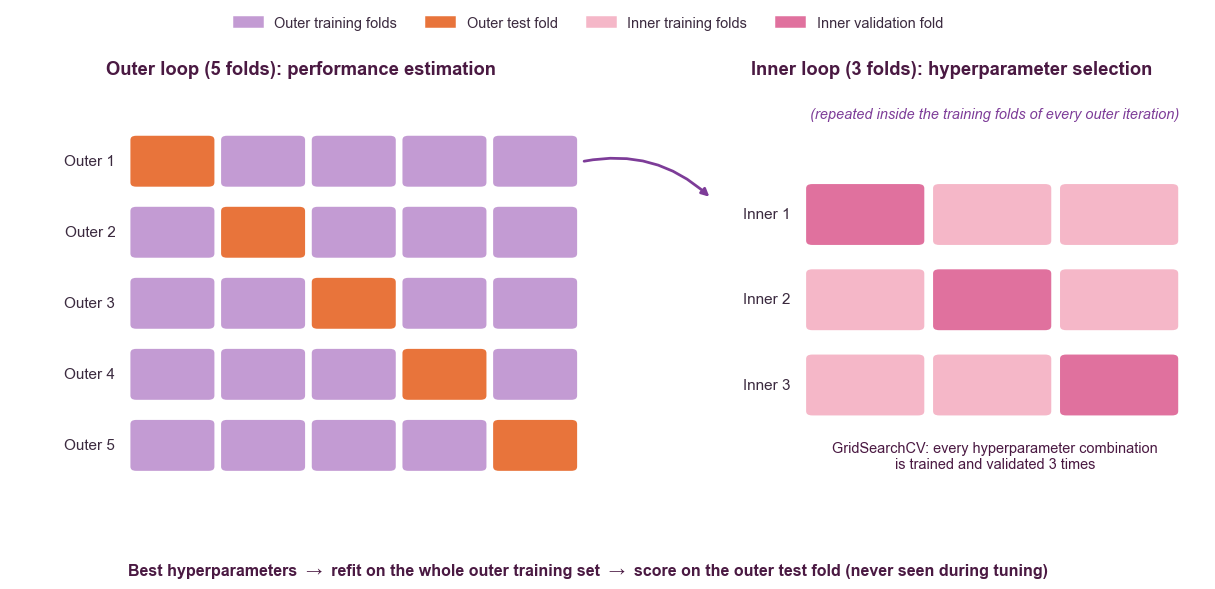

In [4]:
from matplotlib.patches import FancyBboxPatch, ConnectionPatch, Patch

def draw_block(ax, x, y, w, h, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.08",
                                facecolor=color, edgecolor="white", linewidth=2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
for ax in (ax1, ax2):
    ax.set_axis_off()

K_OUT, K_IN = 5, 3
for i in range(K_OUT):
    row = K_OUT - 1 - i
    for j in range(K_OUT):
        draw_block(ax1, j, row + 0.12, 0.96, 0.76, ORANGE if j == i else LILAC)
    ax1.text(-0.15, row + 0.5, f"Outer {i + 1}", ha="right", va="center", fontsize=10)
ax1.set_xlim(-1.3, K_OUT + 0.1)
ax1.set_ylim(-0.6, K_OUT + 0.6)
ax1.set_title("Outer loop (5 folds): performance estimation", fontsize=12)

for i in range(K_IN):
    row = K_IN - 1 - i
    for j in range(K_IN):
        draw_block(ax2, j * 4 / 3, row * 1.2 + 0.9, 4 / 3 - 0.06, 0.9, PINK if j == i else ROSE)
    ax2.text(-0.15, row * 1.2 + 1.35, f"Inner {i + 1}", ha="right", va="center", fontsize=10)
ax2.text(2, 0.35, "GridSearchCV: every hyperparameter combination\nis trained and validated 3 times",
         ha="center", va="center", fontsize=9.5, color=PLUM)
ax2.set_xlim(-1.1, 4.2)
ax2.set_ylim(-0.6, K_OUT + 0.6)
ax2.set_title("Inner loop (3 folds): hyperparameter selection", fontsize=12)
ax2.text(2, K_OUT + 0.1, "(repeated inside the training folds of every outer iteration)",
         ha="center", fontsize=9.5, color=PURPLE, style="italic")

con = ConnectionPatch(xyA=(K_OUT + 0.02, K_OUT - 0.5), coordsA=ax1.transData,
                      xyB=(-1.0, 4.0), coordsB=ax2.transData,
                      arrowstyle="-|>", color=PURPLE, lw=1.8, connectionstyle="arc3,rad=-0.25")
fig.add_artist(con)
fig.text(0.5, 0.02, "Best hyperparameters  →  refit on the whole outer training set  →  "
         "score on the outer test fold (never seen during tuning)",
         ha="center", fontsize=10.5, color=PLUM, weight="semibold")
handles = [Patch(color=LILAC, label="Outer training folds"), Patch(color=ORANGE, label="Outer test fold"),
           Patch(color=ROSE, label="Inner training folds"), Patch(color=PINK, label="Inner validation fold")]
fig.legend(handles=handles, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.02), fontsize=9.5)
save(fig, "nested_cv_diagram.png")
plt.show()

## 3. Models and hyperparameter grids

The models that depend on the scale (linear, KNN, SVR) have a `StandardScaler` inside the Pipeline,
so it is fitted only with the training data of each fold. The grids are small because with nested
CV every combination is trained 5 x 3 times.

In [5]:
def scaled(estimator):
    return Pipeline([("scaler", StandardScaler()), ("model", estimator)])

def plain(estimator):
    return Pipeline([("model", estimator)])

MODELS = {
    "Mean baseline":     (plain(DummyRegressor(strategy="mean")), {}),
    "Linear regression": (scaled(LinearRegression()), {}),
    "Ridge":             (scaled(Ridge()), {"model__alpha": [0.1, 1, 10, 100]}),
    "Lasso":             (scaled(Lasso(max_iter=10000)), {"model__alpha": [0.0005, 0.005, 0.05]}),
    "KNN":               (scaled(KNeighborsRegressor()),
                          {"model__n_neighbors": [10, 25, 50], "model__weights": ["uniform", "distance"]}),
    "Decision tree":     (plain(DecisionTreeRegressor(random_state=SEED)),
                          {"model__max_depth": [3, 5, 8, 12], "model__min_samples_leaf": [5, 20, 50]}),
    "Random forest":     (plain(RandomForestRegressor(n_estimators=300, random_state=SEED)),
                          {"model__max_features": ["sqrt", 0.5], "model__min_samples_leaf": [1, 5]}),
    "Gradient boosting": (plain(HistGradientBoostingRegressor(random_state=SEED)),
                          {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [15, 31]}),
    "SVR":               (scaled(SVR()), {"model__C": [0.3, 1, 3], "model__gamma": ["scale", 0.03]}),
}

FAMILY_COLORS = {"Mean baseline": "#BDB3C2", "Linear regression": PLUM, "Ridge": PURPLE,
                 "Lasso": LILAC, "KNN": APRICOT, "Decision tree": ROSE,
                 "Random forest": PINK, "Gradient boosting": ORANGE, "SVR": "#9C5B8E"}

## 4. Nested cross-validation

For each outer fold we save the test scores, the score of the inner loop and the hyperparameters
chosen by `GridSearchCV`. We also save the out-of-fold predictions (each wine is predicted once,
by a model that didn't see it during training).

In [6]:
outer_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
inner_cv = KFold(n_splits=3, shuffle=True, random_state=SEED)

def short(params):
    return {k.replace("model__", ""): v for k, v in params.items()}

def nested_cv(pipeline, grid, name):
    rows = []
    oof_pred = np.zeros(len(y))
    for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X), start=1):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        # inner loop: grid search with the training part only
        search = GridSearchCV(pipeline, grid, scoring="neg_root_mean_squared_error",
                              cv=inner_cv, n_jobs=-1)
        search.fit(X_train, y_train)
        # test the best model on the outer test fold
        y_hat = search.predict(X_test)
        oof_pred[test_idx] = y_hat
        rows.append({"model": name, "fold": fold,
                     "RMSE": rmse(y_test, y_hat), "MAE": mean_absolute_error(y_test, y_hat),
                     "R2": r2_score(y_test, y_hat), "inner RMSE": -search.best_score_,
                     "best params": short(search.best_params_)})
        print(f"  >fold {fold}: RMSE={rows[-1]['RMSE']:.3f}  inner={-search.best_score_:.3f}  "
              f"cfg={short(search.best_params_)}")
    return pd.DataFrame(rows), oof_pred

In [7]:
import time

fold_results, oof = [], {}
for name, (pipeline, grid) in MODELS.items():
    start = time.time()
    print(name)
    folds, oof[name] = nested_cv(pipeline, grid, name)
    fold_results.append(folds)
    print(f"  RMSE: {folds.RMSE.mean():.3f} ({folds.RMSE.std():.3f})   [{time.time() - start:.0f}s]\n")

folds_df = pd.concat(fold_results, ignore_index=True)

Mean baseline


  >fold 1: RMSE=0.868  inner=0.883  cfg={}


  >fold 2: RMSE=0.869  inner=0.882  cfg={}
  >fold 3: RMSE=0.874  inner=0.881  cfg={}


  >fold 4: RMSE=0.889  inner=0.878  cfg={}
  >fold 5: RMSE=0.901  inner=0.874  cfg={}
  RMSE: 0.880 (0.015)   [5s]

Linear regression
  >fold 1: RMSE=0.721  inner=0.737  cfg={}


  >fold 2: RMSE=0.713  inner=0.739  cfg={}
  >fold 3: RMSE=0.731  inner=0.733  cfg={}
  >fold 4: RMSE=0.751  inner=0.729  cfg={}
  >fold 5: RMSE=0.748  inner=0.732  cfg={}
  RMSE: 0.733 (0.016)   [1s]

Ridge
  >fold 1: RMSE=0.722  inner=0.736  cfg={'alpha': 100}


  >fold 2: RMSE=0.714  inner=0.738  cfg={'alpha': 100}
  >fold 3: RMSE=0.731  inner=0.733  cfg={'alpha': 1}
  >fold 4: RMSE=0.751  inner=0.729  cfg={'alpha': 10}
  >fold 5: RMSE=0.747  inner=0.732  cfg={'alpha': 100}
  RMSE: 0.733 (0.016)   [0s]

Lasso


... (20 outputs left out)

  >fold 2: RMSE=0.678  inner=0.698  cfg={'C': 1, 'gamma': 'scale'}


  >fold 3: RMSE=0.696  inner=0.700  cfg={'C': 1, 'gamma': 'scale'}


  >fold 4: RMSE=0.711  inner=0.695  cfg={'C': 1, 'gamma': 'scale'}


  >fold 5: RMSE=0.706  inner=0.694  cfg={'C': 1, 'gamma': 'scale'}
  RMSE: 0.694 (0.015)   [9s]



## 5. Results and confidence intervals

For each model we have five outer scores (mean and standard deviation). We also compute a 95%
bootstrap confidence interval: we resample the out-of-fold predictions 1,000 times and take the
2.5 and 97.5 percentiles.

In [8]:
def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, seed=42):
    # 95% confidence interval by resampling the out-of-fold predictions
    rng = np.random.default_rng(seed)
    n = len(y_true)
    values = [metric(y_true[idx], y_pred[idx])
              for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(values, [2.5, 97.5])

In [9]:
rows = []
for name in MODELS:
    f = folds_df[folds_df.model == name]
    lo, hi = bootstrap_ci(y, oof[name], rmse)
    r2_lo, r2_hi = bootstrap_ci(y, oof[name], r2_score)
    rows.append({"Model": name,
                 "RMSE mean": f.RMSE.mean(), "RMSE std": f.RMSE.std(),
                 "RMSE 95% CI low": lo, "RMSE 95% CI high": hi,
                 "MAE mean": f.MAE.mean(), "R2 mean": f.R2.mean(),
                 "R2 95% CI low": r2_lo, "R2 95% CI high": r2_hi})
summary = pd.DataFrame(rows).set_index("Model").sort_values("RMSE mean")
summary.to_csv(RES_DIR / "regression_nested_summary.csv")
folds_df.to_csv(RES_DIR / "regression_nested_folds.csv", index=False)
pd.DataFrame(oof).assign(y_true=y).to_csv(RES_DIR / "regression_oof_predictions.csv", index=False)
summary.round(3)

,RMSE mean,RMSE std,RMSE 95% CI low,RMSE 95% CI high,MAE mean,R2 mean,R2 95% CI low,R2 95% CI high
Model,,,,,,,,
Random forest,0.680,0.014,0.663,0.696,0.523,0.401,0.383,0.421
Gradient boosting,0.689,0.018,0.673,0.706,0.536,0.384,0.366,0.406
SVR,0.694,0.015,0.677,0.710,0.527,0.377,0.357,0.398
KNN,0.704,0.018,0.688,0.720,0.547,0.358,0.339,0.378
Lasso,0.733,0.016,0.716,0.749,0.566,0.305,0.287,0.327
Linear regression,0.733,0.016,0.716,0.749,0.566,0.305,0.286,0.327
Ridge,0.733,0.016,0.716,0.750,0.567,0.304,0.286,0.325
Decision tree,0.750,0.013,0.734,0.768,0.581,0.271,0.249,0.293
Mean baseline,0.880,0.015,0.862,0.897,0.695,-0.004,-0.003,-0.001


Figure saved -> ../results/figures/reg_model_comparison_ci.png


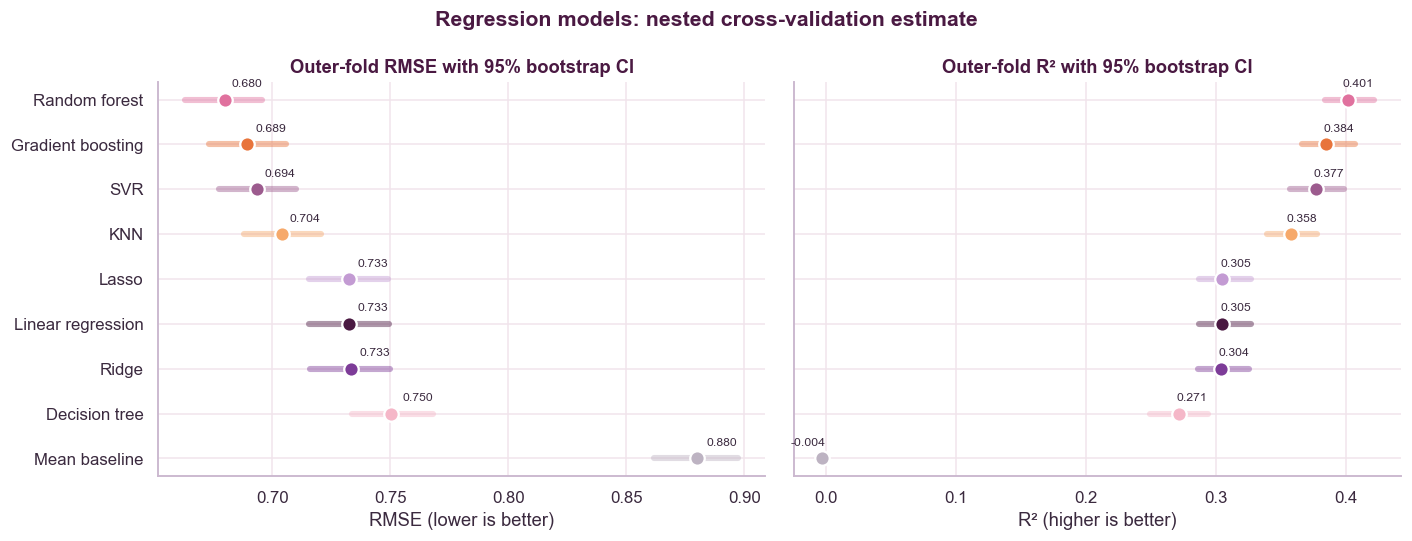

In [10]:
order = summary.index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, metric, lo, hi, label in [
        (axes[0], "RMSE mean", "RMSE 95% CI low", "RMSE 95% CI high", "RMSE (lower is better)"),
        (axes[1], "R2 mean", "R2 95% CI low", "R2 95% CI high", "R² (higher is better)")]:
    for i, name in enumerate(order):
        ax.plot([summary.loc[name, lo], summary.loc[name, hi]], [i, i], color=FAMILY_COLORS[name],
                lw=4, alpha=0.45, solid_capstyle="round")
        ax.scatter(summary.loc[name, metric], i, s=90, color=FAMILY_COLORS[name],
                   edgecolor="white", linewidth=1.5, zorder=3)
        ax.text(summary.loc[name, hi], i + 0.28, f"{summary.loc[name, metric]:.3f}",
                fontsize=8, ha="right", color=INK)
    ax.set_xlabel(label)
axes[0].set_yticks(range(len(order)), order)
axes[0].set_title("Outer-fold RMSE with 95% bootstrap CI")
axes[1].set_title("Outer-fold R² with 95% bootstrap CI")
fig.suptitle("Regression models: nested cross-validation estimate",
             color=PLUM, weight="semibold", fontsize=14)
fig.tight_layout()
save(fig, "reg_model_comparison_ci.png")
plt.show()

Figure saved -> ../results/figures/reg_outer_fold_scores.png


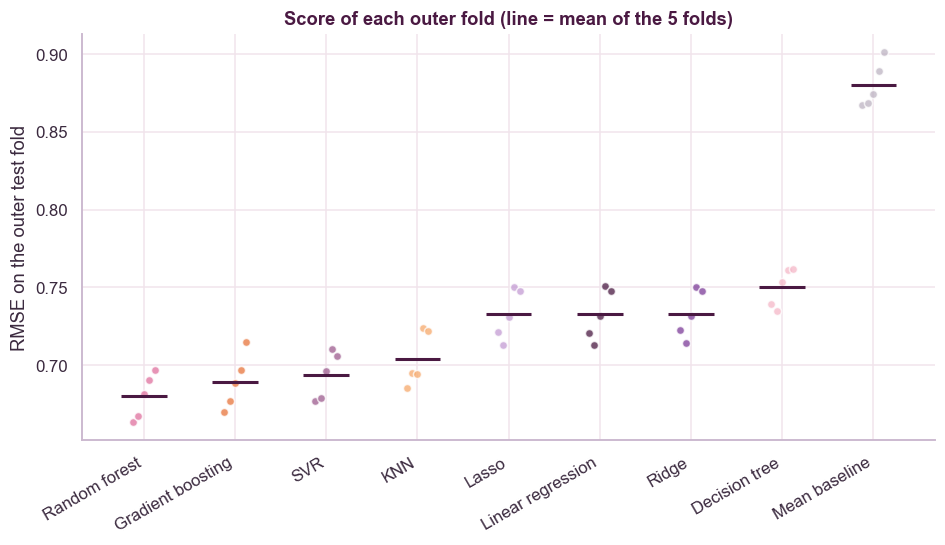

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.8))
order = summary.index
for i, name in enumerate(order):
    vals = folds_df.loc[folds_df.model == name, "RMSE"]
    ax.scatter(np.full(len(vals), i) + np.linspace(-0.12, 0.12, len(vals)), vals, s=28,
               color=FAMILY_COLORS[name], alpha=0.75, edgecolor="white")
    ax.hlines(vals.mean(), i - 0.25, i + 0.25, color=PLUM, lw=2)
ax.set_xticks(range(len(order)), order, rotation=30, ha="right")
ax.set_ylabel("RMSE on the outer test fold")
ax.set_title("Score of each outer fold (line = mean of the 5 folds)")
save(fig, "reg_outer_fold_scores.png")
plt.show()

## Paired comparison of the best model with the others

Overlapping confidence intervals do not mean that two models are equal. Both models are
evaluated on the same wines, so their errors are correlated. A paired bootstrap resamples the
wines once and computes the metric of the two models on the same resample, which gives a
confidence interval for the difference itself. If the interval does not contain 0, the
difference is significant at the 5% level.

In [12]:
def paired_bootstrap(y_true, pred_a, pred_b, metric, n_boot=2000, seed=42):
    # same resampled wines for both models -> distribution of metric(a) - metric(b)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        diffs[b] = metric(y_true[idx], pred_a[idx]) - metric(y_true[idx], pred_b[idx])
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return metric(y_true, pred_a) - metric(y_true, pred_b), lo, hi

best_name = summary.index[0]
rows = []
for other in summary.index[1:]:
    d, lo, hi = paired_bootstrap(y, oof[best_name], oof[other], rmse)
    rows.append({"comparison": f"{best_name} - {other}", "difference": d, "CI low": lo, "CI high": hi})
paired = pd.DataFrame(rows).set_index("comparison")
paired.to_csv(RES_DIR / "regression_paired_bootstrap.csv")
paired.round(3)

,difference,CI low,CI high
comparison,,,
Random forest - Gradient boosting,-0.010,-0.014,-0.005
Random forest - SVR,-0.014,-0.020,-0.008
Random forest - KNN,-0.024,-0.030,-0.019
Random forest - Lasso,-0.053,-0.061,-0.044
Random forest - Linear regression,-0.053,-0.061,-0.044
Random forest - Ridge,-0.053,-0.062,-0.045
Random forest - Decision tree,-0.070,-0.078,-0.062
Random forest - Mean baseline,-0.200,-0.212,-0.188


Figure saved -> ../results/figures/reg_paired_bootstrap.png


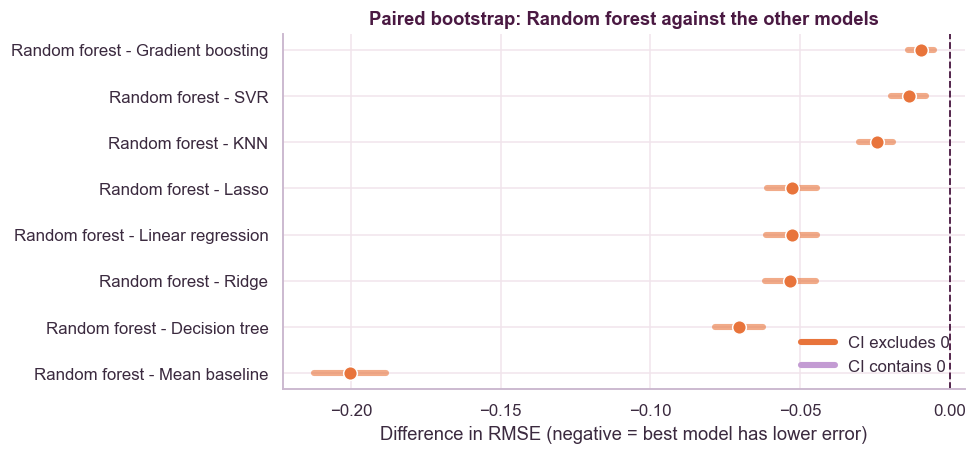

In [13]:
XLABEL = "Difference in RMSE (negative = best model has lower error)"
FIGNAME = "reg_paired_bootstrap.png"
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, (name, row) in enumerate(paired.iloc[::-1].iterrows()):
    sig = (row["CI low"] > 0) or (row["CI high"] < 0)
    color = ORANGE if sig else LILAC
    ax.plot([row["CI low"], row["CI high"]], [i, i], color=color, lw=4, alpha=0.6, solid_capstyle="round")
    ax.scatter(row["difference"], i, s=80, color=color, edgecolor="white", zorder=3)
ax.axvline(0, color=PLUM, lw=1.2, ls="--")
ax.set_yticks(range(len(paired)), paired.index[::-1])
ax.set_xlabel(XLABEL)
ax.set_title(f"Paired bootstrap: {best_name} against the other models")
handles = [plt.Line2D([], [], color=ORANGE, lw=4, label="CI excludes 0"),
           plt.Line2D([], [], color=LILAC, lw=4, label="CI contains 0")]
ax.legend(handles=handles, loc="lower right")
save(fig, FIGNAME)
plt.show()

## 6. Hyperparameters chosen in each outer fold

Each outer fold runs its own grid search, so the chosen hyperparameters can be different between
folds.

In [14]:
params_table = (folds_df[folds_df["best params"].map(len) > 0]
                .assign(params=lambda d: d["best params"].map(lambda p: ", ".join(f"{k}={v}" for k, v in p.items())))
                .pivot(index="model", columns="fold", values="params"))
params_table.columns = [f"Outer fold {c}" for c in params_table.columns]
params_table = params_table.loc[[m for m in summary.index if m in params_table.index]]
params_table.to_csv(RES_DIR / "regression_best_params_per_fold.csv")
params_table

,Outer fold 1,Outer fold 2,Outer fold 3,Outer fold 4,Outer fold 5
model,,,,,
Random forest,"max_features=sqrt, min_samples_leaf=1","max_features=sqrt, min_samples_leaf=1","max_features=sqrt, min_samples_leaf=1","max_features=sqrt, min_samples_leaf=1","max_features=sqrt, min_samples_leaf=1"
Gradient boosting,"learning_rate=0.05, max_leaf_nodes=31","learning_rate=0.05, max_leaf_nodes=31","learning_rate=0.05, max_leaf_nodes=31","learning_rate=0.05, max_leaf_nodes=31","learning_rate=0.05, max_leaf_nodes=31"
SVR,"C=1, gamma=scale","C=1, gamma=scale","C=1, gamma=scale","C=1, gamma=scale","C=1, gamma=scale"
KNN,"n_neighbors=25, weights=distance","n_neighbors=25, weights=distance","n_neighbors=25, weights=distance","n_neighbors=25, weights=distance","n_neighbors=25, weights=distance"
Lasso,alpha=0.0005,alpha=0.0005,alpha=0.0005,alpha=0.0005,alpha=0.0005
Ridge,alpha=100,alpha=100,alpha=1,alpha=10,alpha=100
Decision tree,"max_depth=5, min_samples_leaf=50","max_depth=5, min_samples_leaf=50","max_depth=5, min_samples_leaf=50","max_depth=8, min_samples_leaf=50","max_depth=5, min_samples_leaf=20"


## 7. Best model and final model

* The best model is the one with the lowest mean RMSE. We check if its confidence interval
  overlaps with the second one; if it does, we can't say it is clearly better.
* The inner loops can choose different hyperparameters, so to get the final ones we run the same
  `GridSearchCV` again on all the data and train the final model with them.
* The expected performance of this final model is the nested CV result.

In [15]:
best_name, second_name = summary.index[0], summary.index[1]
b, s = summary.loc[best_name], summary.loc[second_name]
overlap = b["RMSE 95% CI high"] >= s["RMSE 95% CI low"]
print(f"Best model : {best_name}  RMSE {b['RMSE mean']:.3f}  "
      f"CI [{b['RMSE 95% CI low']:.3f}, {b['RMSE 95% CI high']:.3f}]")
print(f"Second     : {second_name}  RMSE {s['RMSE mean']:.3f}  "
      f"CI [{s['RMSE 95% CI low']:.3f}, {s['RMSE 95% CI high']:.3f}]")
print("Confidence intervals overlap:", overlap)

pipeline, grid = MODELS[best_name]
final_search = GridSearchCV(pipeline, grid, scoring="neg_root_mean_squared_error",
                            cv=KFold(n_splits=5, shuffle=True, random_state=SEED), n_jobs=-1)
final_search.fit(X, y)
final_model = final_search.best_estimator_
print("\nFinal hyperparameters (GridSearchCV on all data):", short(final_search.best_params_))

Best model : Random forest  RMSE 0.680  CI [0.663, 0.696]
Second     : Gradient boosting  RMSE 0.689  CI [0.673, 0.706]
Confidence intervals overlap: True



Final hyperparameters (GridSearchCV on all data): {'max_features': 'sqrt', 'min_samples_leaf': 1}


## 8. Analysis of the best model

Figure saved -> ../results/figures/reg_predicted_vs_actual.png


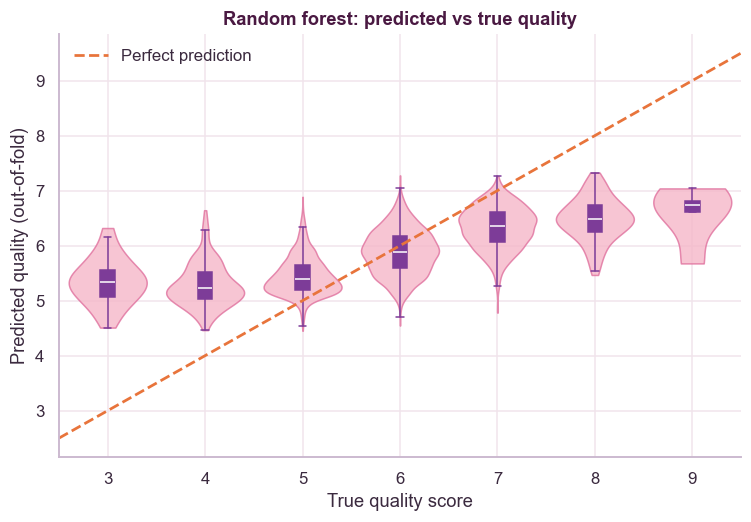

In [16]:
pred = oof[best_name]
fig, ax = plt.subplots(figsize=(8, 5))
scores = np.sort(np.unique(y))
data = [pred[y == q] for q in scores]
parts = ax.violinplot(data, positions=scores, widths=0.8, showextrema=False)
for body in parts["bodies"]:
    body.set_facecolor(ROSE)
    body.set_edgecolor(PINK)
    body.set_alpha(0.8)
ax.boxplot(data, positions=scores, widths=0.15, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor=PURPLE, color=PURPLE), medianprops=dict(color="white"),
           whiskerprops=dict(color=PURPLE), capprops=dict(color=PURPLE))
ax.plot([2.5, 9.5], [2.5, 9.5], ls="--", color=ORANGE, lw=1.8, label="Perfect prediction")
ax.set_xlabel("True quality score")
ax.set_ylabel("Predicted quality (out-of-fold)")
ax.set_title(f"{best_name}: predicted vs true quality")
ax.legend(loc="upper left")
save(fig, "reg_predicted_vs_actual.png")
plt.show()

Figure saved -> ../results/figures/reg_residuals.png


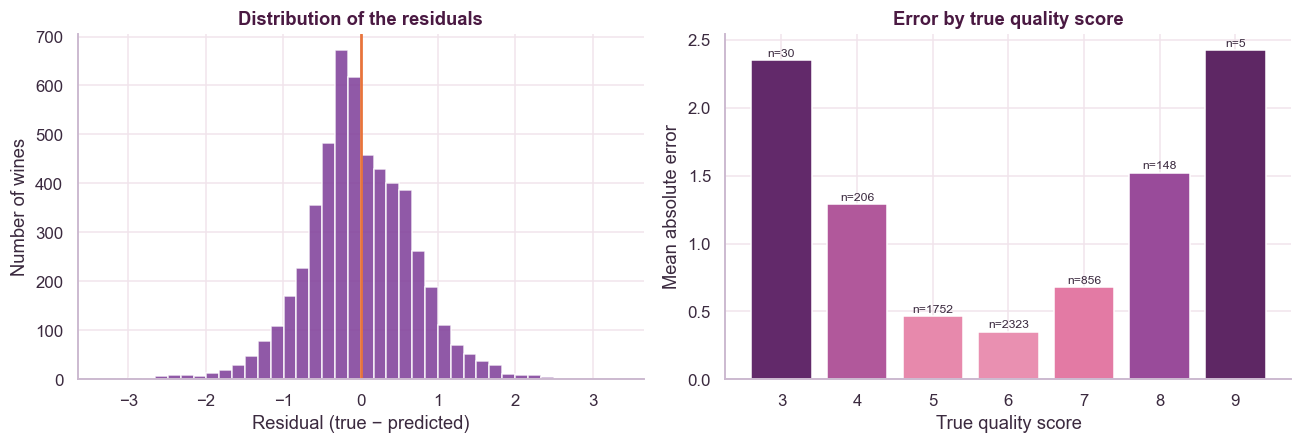

In [17]:
residuals = y - pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(residuals, bins=40, color=PURPLE, alpha=0.85, edgecolor="white")
axes[0].axvline(0, color=ORANGE, lw=1.8)
axes[0].set_xlabel("Residual (true − predicted)")
axes[0].set_ylabel("Number of wines")
axes[0].set_title("Distribution of the residuals")

err = pd.DataFrame({"q": y, "abs": np.abs(residuals)}).groupby("q")["abs"].agg(["mean", "size"])
axes[1].bar(err.index, err["mean"], color=[CMAP_SEQ(0.3 + 0.6 * v / err["mean"].max()) for v in err["mean"]],
            edgecolor="white")
for qv, row in err.iterrows():
    axes[1].text(qv, row["mean"] + 0.03, f"n={int(row['size'])}", ha="center", fontsize=8)
axes[1].set_xlabel("True quality score")
axes[1].set_ylabel("Mean absolute error")
axes[1].set_title("Error by true quality score")
fig.tight_layout()
save(fig, "reg_residuals.png")
plt.show()

,impurity,permutation,permutation std
alcohol,0.182,0.121,0.007
volatile acidity,0.102,0.048,0.005
free sulfur dioxide,0.090,0.043,0.003
sulphates,0.077,0.025,0.002
density,0.110,0.025,0.003
total sulfur dioxide,0.080,0.021,0.001
chlorides,0.082,0.017,0.004
citric acid,0.070,0.017,0.002
residual sugar,0.071,0.014,0.001
pH,0.069,0.012,0.002


Figure saved -> ../results/figures/reg_feature_importance.png


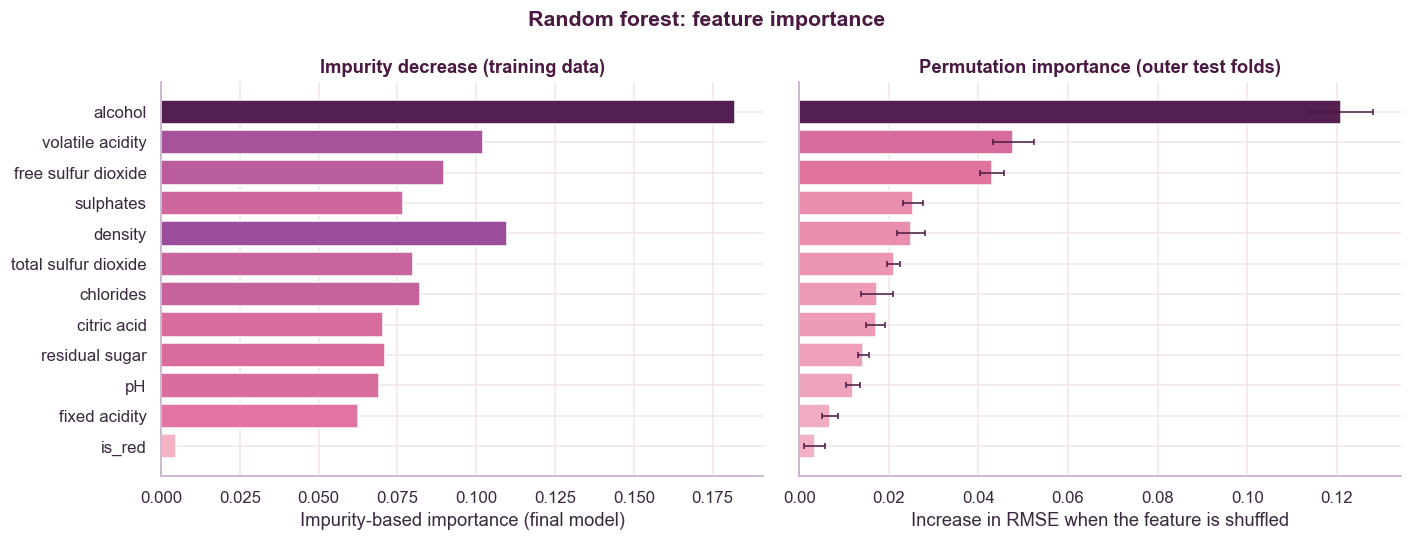

In [18]:
from sklearn.inspection import permutation_importance

SPLIT_ARGS = (X,)
PERM_SCORING = "neg_root_mean_squared_error"
PERM_LABEL = "Increase in RMSE when the feature is shuffled"
IMP_CSV, IMP_FIG = "regression_feature_importance.csv", "reg_feature_importance.png"
impurity = (pd.Series(final_model.named_steps["model"].feature_importances_, index=FEATURES)
            if hasattr(final_model.named_steps["model"], "feature_importances_") else None)

# permutation importance measured on the outer test folds, with the model of each fold
perm_rows = []
for fold, (train_idx, test_idx) in enumerate(outer_cv.split(*SPLIT_ARGS), start=1):
    params = folds_df[(folds_df.model == best_name) & (folds_df.fold == fold)]["best params"].iloc[0]
    fold_model = clone(MODELS[best_name][0]).set_params(**{f"model__{k}": v for k, v in params.items()})
    fold_model.fit(X[train_idx], y[train_idx])
    r = permutation_importance(fold_model, X[test_idx], y[test_idx], scoring=PERM_SCORING,
                               n_repeats=10, random_state=SEED, n_jobs=-1)
    perm_rows.append(r.importances_mean)
perm = pd.Series(np.mean(perm_rows, axis=0), index=FEATURES)
perm_std = pd.Series(np.std(perm_rows, axis=0), index=FEATURES)

importance = pd.DataFrame({"impurity": impurity, "permutation": perm, "permutation std": perm_std})
importance.round(4).to_csv(RES_DIR / IMP_CSV)
display(importance.sort_values("permutation", ascending=False).round(3))

order = perm.sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
axes[0].barh(order, impurity[order], color=[CMAP_SEQ(0.25 + 0.7 * v / impurity.max()) for v in impurity[order]],
             edgecolor="white")
axes[0].set_xlabel("Impurity-based importance (final model)")
axes[0].set_title("Impurity decrease (training data)")
axes[1].barh(order, perm[order], xerr=perm_std[order], color=[CMAP_SEQ(0.25 + 0.7 * max(v, 0) / perm.max()) for v in perm[order]],
             edgecolor="white", error_kw=dict(ecolor=PLUM, lw=1, capsize=2))
axes[1].set_xlabel(PERM_LABEL)
axes[1].set_title("Permutation importance (outer test folds)")
fig.suptitle(f"{best_name}: feature importance", color=PLUM, weight="semibold", fontsize=14)
fig.tight_layout()
save(fig, IMP_FIG)
plt.show()

## Summary

* All the models were tuned only with the training data of each outer fold and evaluated on a fold
  they had never seen.
* The results are saved in `../results/regression_nested_summary.csv`.
* The final model is the best one, tuned again with `GridSearchCV` on all the data.